# 01 · Weather behaviour, hazard indicators and validation
**Ukame Watch** · eight arid counties of northern Kenya · Challenge 1: Climate Sentinel

This notebook reads the outputs of `python tools/build_all.py` (which calls the tested functions in
`src/ukame/analysis.py` and `validation.py`). Rainfall and temperature are **NASA POWER (MERRA-2) reanalysis:
model-based, not station data**. Normals: 1991–2020.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from ukame import config as C
P = C.PROCESSED
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1B1D1C", "#898781", "#e1e0d9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110})
def pct_colour(p):
    for upper, col in [(50,"#b8302f"),(75,"#e34948"),(90,"#ee9288"),(110,"#d6d5cf"),(150,"#9ec5f4"),(200,"#5598e7"),(1e9,"#1c5cab")]:
        if p < upper: return col

## 1. Data coverage and quality

In [2]:
counties = pd.read_csv(P/"counties.csv"); pop = pd.read_csv(P/"population.csv")
display(counties.merge(pop[["county","census_2019","worldpop_2020","worldpop_to_census_ratio"]], on="county"))
display(pd.read_csv(P/"quality_report.csv"))

,county,iso,lat,lon,area_km2,census_2019,worldpop_2020,worldpop_to_census_ratio
0,Turkana,KE-43,3.4110,35.4351,69746.0,926976,1259553,1.36
1,Marsabit,KE-25,2.9795,37.5681,75927.0,459785,364649,0.79
2,Mandera,KE-24,3.4381,40.7368,26016.0,867457,2666755,3.07
3,Wajir,KE-46,1.8091,40.0336,56704.0,781263,1742496,2.23
4,Samburu,KE-37,1.3196,37.1167,21079.0,310327,330921,1.07
5,Isiolo,KE-09,1.0116,38.5392,25351.0,268002,184988,0.69
6,Garissa,KE-07,-0.4884,40.1806,44825.0,841353,1630158,1.94
7,Kitui,KE-18,-1.4857,38.4058,30556.0,1136187,1273454,1.12


,county,first_date,last_date,days,missing_dates,missing_rain,missing_tmax,negative_rain,tmin_above_tmax,duplicate_dates
0,Garissa,1991-01-01,2026-11-09,13097,0,0,0,0,0,0
1,Isiolo,1991-01-01,2026-11-09,13097,0,0,0,0,0,0
2,Kitui,1991-01-01,2026-11-09,13097,0,0,0,0,0,0
3,Mandera,1991-01-01,2026-11-09,13097,0,0,0,0,0,0
4,Marsabit,1991-01-01,2026-11-09,13097,0,0,0,0,0,0
5,Samburu,1991-01-01,2026-11-09,13097,0,0,0,0,0,0
6,Turkana,1991-01-01,2026-11-09,13097,0,0,0,0,0,0
7,Wajir,1991-01-01,2026-11-09,13097,0,0,0,0,0,0


### Rainfall QC: spurious one-day spikes
NASA POWER contains a few physically implausible days that a second reanalysis (ERA5) does not see.
Candidates (> 100 mm) where ERA5 shows less than 10% of the value are replaced with the ERA5 value.

In [3]:
qc = pd.read_csv(P/"qc_rainfall_flags.csv"); display(qc)
print(qc["action"].value_counts().to_string())
display(pd.read_csv(P/"crosscheck_era5.csv"))

,county,date,original_mm,era5_mm,action
0,Turkana,2020-12-31,608.50,1.0,replaced with ERA5
1,Turkana,2021-01-01,110.64,6.0,replaced with ERA5
2,Marsabit,2021-01-01,145.37,0.1,replaced with ERA5
3,Wajir,2021-11-27,485.95,14.4,replaced with ERA5
4,Wajir,2021-11-28,321.31,9.3,replaced with ERA5
5,Wajir,2021-11-29,187.70,6.0,replaced with ERA5
6,Wajir,2022-04-20,481.44,14.3,replaced with ERA5
7,Wajir,2023-06-05,262.09,0.0,replaced with ERA5
8,Wajir,2023-06-09,122.00,0.5,replaced with ERA5
9,Mandera,2021-11-27,564.23,17.8,replaced with ERA5


action
replaced with ERA5           11
kept (ERA5 confirms rain)     1


,county,days_compared,daily_correlation,monthly_correlation,mean_annual_era5_mm,mean_annual_power_mm
0,Marsabit,13094,0.337,0.718,132.0,330.0
1,Turkana,13094,0.348,0.695,390.0,344.0


## 2. Monthly climatology (1991–2020 normals)

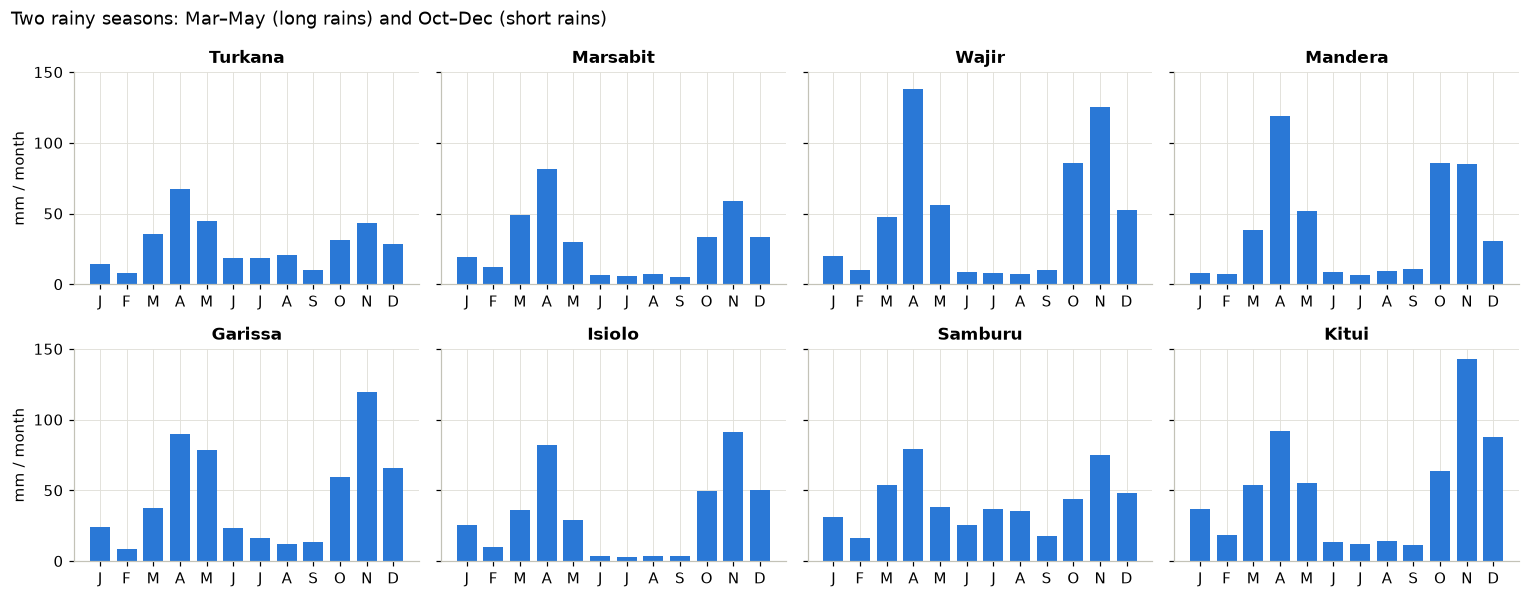

In [4]:
clim = pd.read_csv(P/"climatology.csv")
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharey=True)
for ax, c in zip(axes.flat, C.COUNTIES):
    g = clim[clim.county == c]
    ax.bar(g.month, g.rain_normal_mm, color=BLUE, width=0.75)
    ax.set_title(c); ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
axes[0,0].set_ylabel("mm / month"); axes[1,0].set_ylabel("mm / month")
fig.suptitle("Two rainy seasons: Mar–May (long rains) and Oct–Dec (short rains)", x=0.01, ha="left"); plt.tight_layout()

## 3. Seasons and trends (Mann-Kendall test, Sen's slope per decade)

In [5]:
tr = pd.read_csv(P/"trends.csv")
print(f"{tr.significant_5pct.sum()} of {len(tr)} tests significant at p < 0.05 (about {0.05*len(tr):.0f} expected by chance)")
display(tr.pivot_table(index="county", columns="variable", values="sen_slope_per_decade").round(2))
display(tr[tr.significant_5pct][["county","variable","trend","p_value","sen_slope_per_decade"]])

15 of 64 tests significant at p < 0.05 (about 3 expected by chance)


variable,MAM_rain_mm,OND_rain_mm,annual_rain_mm,heat_days,heavy_rain_days,longest_dry_spell_days,max_3day_rain_mm,mean_tmax_c
county,,,,,,,,
Garissa,9.14,-23.37,-24.73,6.67,0.77,0.91,1.58,0.26
Isiolo,-3.91,-11.51,-17.88,5.77,0.00,-1.48,3.69,0.34
Kitui,-5.04,-23.97,-38.49,6.67,0.00,-0.56,2.98,0.31
Mandera,3.17,-0.52,7.86,5.00,0.00,-2.38,2.50,0.18
Marsabit,-14.29,-0.55,-28.27,6.88,0.00,4.21,-0.19,0.35
Samburu,-5.81,-18.82,-49.07,10.00,0.00,4.74,3.33,0.30
Turkana,29.15,10.25,34.90,3.33,1.11,-1.20,14.57,0.10
Wajir,-16.25,-20.56,-39.57,5.26,0.00,2.58,4.99,0.24


,county,variable,trend,p_value,sen_slope_per_decade
6,Garissa,heat_days,increasing,0.0035,6.667
7,Garissa,mean_tmax_c,increasing,0.0135,0.264
14,Isiolo,heat_days,increasing,0.0026,5.769
15,Isiolo,mean_tmax_c,increasing,0.0004,0.335
22,Kitui,heat_days,increasing,0.0027,6.667
23,Kitui,mean_tmax_c,increasing,0.0008,0.310
30,Mandera,heat_days,increasing,0.0105,5.000
38,Marsabit,heat_days,increasing,0.0021,6.875
39,Marsabit,mean_tmax_c,increasing,0.0001,0.348
46,Samburu,heat_days,increasing,0.0000,10.000


**Reading:** temperature trends dominate. Hot days and mean maximum temperature rise significantly in most
counties; seasonal rainfall totals show no significant trend in any county.

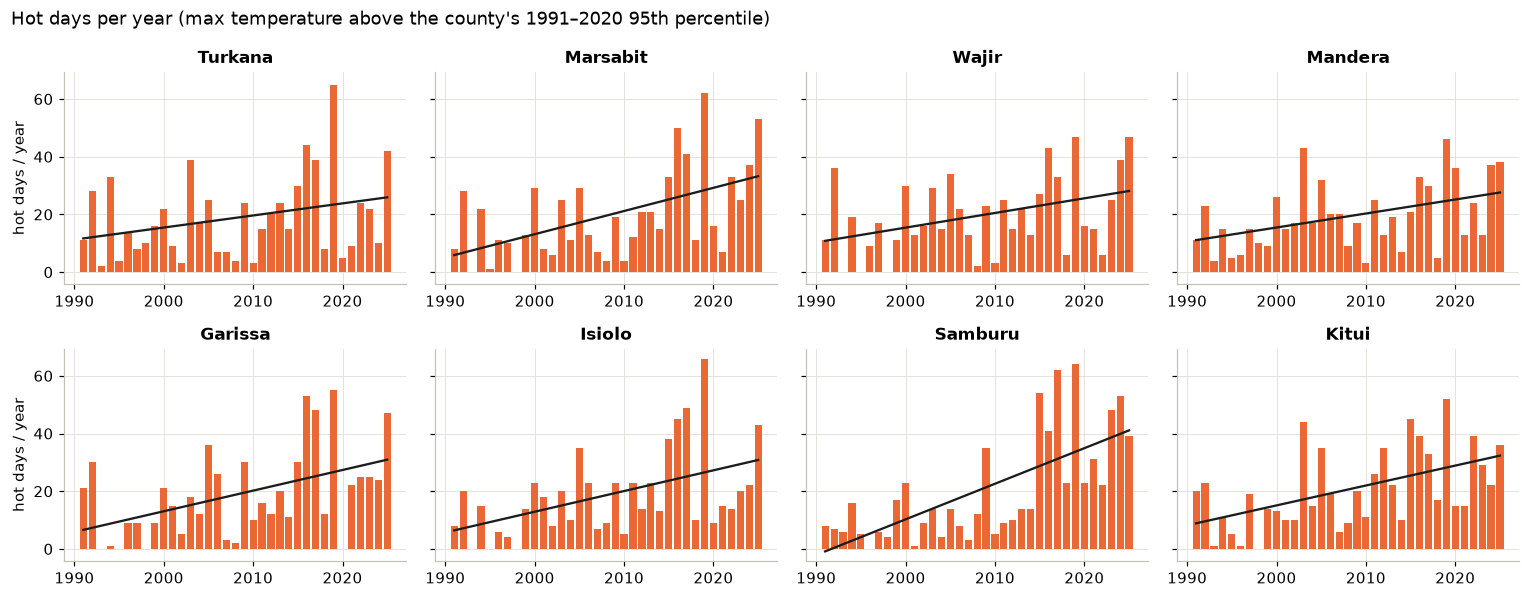

In [6]:
an = pd.read_csv(P/"annual.csv")
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharey=True)
for ax, c in zip(axes.flat, C.COUNTIES):
    g = an[an.county == c]
    ax.bar(g.year, g.heat_days, color=ORANGE, width=0.8)
    z = np.polyfit(g.year, g.heat_days, 1); ax.plot(g.year, np.polyval(z, g.year), color=INK, lw=1.5)
    ax.set_title(c)
axes[0,0].set_ylabel("hot days / year"); axes[1,0].set_ylabel("hot days / year")
fig.suptitle("Hot days per year (max temperature above the county's 1991–2020 95th percentile)", x=0.01, ha="left"); plt.tight_layout()

## 4. Extremes: longest dry spell, heavy-rain days, maximum 3-day rainfall

In [7]:
display(an.groupby("county")[["longest_dry_spell_days","heavy_rain_days","max_3day_rain_mm"]].agg(["mean","max"]).round(1))
display(pd.read_csv(P/"thresholds.csv"))

longest_dry_spell_days        heavy_rain_days       max_3day_rain_mm       
                           mean    max            mean   max             mean    max
county                                                                              
Garissa                    60.3  105.0             6.3  20.0             50.1  155.7
Isiolo                    102.5  167.0             4.3  20.0             48.2  160.9
Kitui                      49.4  116.0             6.4  17.0             48.2  106.9
Mandera                    77.3  134.0             4.9  21.0             61.0  144.9
Marsabit                   88.5  193.0             3.9  13.0             40.9   99.7
Samburu                    41.3   97.0             6.7  18.0             39.4  107.6
Turkana                    64.9  143.0             4.0  14.0             52.9  107.9
Wajir                      70.4  129.0             5.1  22.0             60.5  119.9

,county,heavy_day_p95_mm,rain_3day_p99_mm,heat_tmax_p95_c
0,Garissa,12.2,35.7,38.7
1,Isiolo,12.3,31.4,38.0
2,Kitui,12.8,37.5,34.6
3,Mandera,15.5,40.3,36.6
4,Marsabit,11.4,28.2,38.4
5,Samburu,8.8,26.6,32.9
6,Turkana,12.0,30.1,38.1
7,Wajir,16.3,46.9,38.4


## 5. Hazard indicators
- **Drought:** 3-month rainfall as % of the 1991–2020 normal for the same months (not assessed when the normal is under 30 mm).
- **Heavy rain:** 3-day total above the county's 99th percentile (normal period only).
- **Heat:** max temperature above the county's 95th percentile.

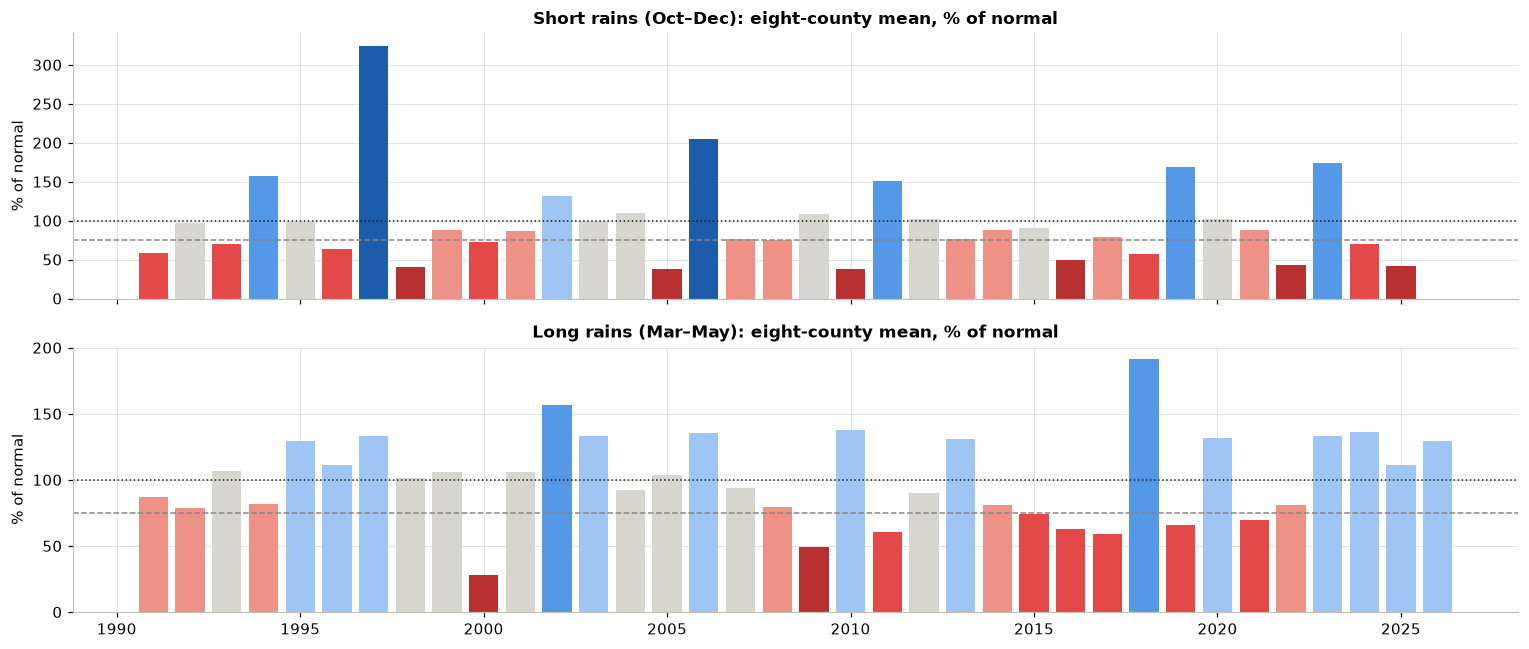

In [8]:
tm = pd.read_csv(P/"three_month.csv")
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, (m, name) in zip(axes, [(12, "Short rains (Oct–Dec)"), (5, "Long rains (Mar–May)")]):
    g = tm[(tm.month == m)].pivot_table(index="year", columns="county", values="pct_normal").mean(axis=1)
    ax.bar(g.index, g.values, color=[pct_colour(v) for v in g.values], width=0.8)
    ax.axhline(100, color=INK, ls=":", lw=1); ax.axhline(75, color=MUTED, ls="--", lw=1)
    ax.set_title(name + ": eight-county mean, % of normal"); ax.set_ylabel("% of normal")
plt.tight_layout()

## 6. Validation against documented events

In [9]:
vd = pd.read_csv(P/"validation_documented.csv")
ev = pd.read_csv(C.REFERENCE/"documented_events.csv")[["event_id","listed","source_title"]]
display(vd.merge(ev, on="event_id")[["event_id","label","indicator_value","threshold","detected","listed","source_title"]])
print(f"Detected {vd.detected.sum()} of {len(vd)} documented events")
display(pd.read_csv(P/"validation_top_periods.csv"))
rd = pd.read_csv(P/"regional_drought_pct.csv")
print(f"{(rd.value < 75).sum()} of {len(rd)} rainy seasons fall below the 75% drought signal (false-alarm context)")

,event_id,label,indicator_value,threshold,detected,listed,source_title
0,D1,2010-11 Horn of Africa drought,37.686715,< 75%,True,before analysis,NOAA Climate.gov: Two Failed Rainy Seasons Lea...
1,D2,2016-17 drought (national disaster declared Fe...,49.502725,< 75%,True,before analysis,World Weather Attribution: Severe drought in K...
2,D3,2020-21 drought (national disaster declared Se...,70.011454,< 75%,True,before analysis,ACAPS Thematic report: Kenya - Impact of droug...
3,D4,2000 long rains failure (worst drought in 37 y...,28.324306,< 75%,True,after indicator flagged it; verified independe...,FAO GIEWS Foodcrops & Shortages: Kenya (18 Sep...
4,D5,2005-06 drought (national disaster declared Ja...,37.589176,< 75%,True,after indicator flagged it; verified independe...,FAO GIEWS Special Alert: Kenya (Jan 2006)
5,F1,1997 El Nino short rains,111.000000,>= 32.6,True,before analysis,"Wainwright et al. (2020), Weather: the excepti..."
6,F2,2019 short rains floods (strong positive IOD),45.000000,>= 32.6,True,before analysis,UN OCHA Kenya Flash Update #1: Floods (30 Oct ...
7,F3,2023 El Nino floods (Garissa / Mandera / Wajir...,53.000000,>= 32.6,True,before analysis,ECHO Daily Flash 23 Nov 2023 (ReliefWeb)
8,F4,2024 long rains floods,50.000000,>= 32.6,True,before analysis,UN OCHA Eastern Africa Heavy Rains and Floodin...
9,F5,2023 long rains flash floods in northern counties,49.000000,>= 32.6,True,after indicator flagged it; verified independe...,Kenya Red Cross / IFRC DREF operation MDRKE056...


Detected 10 of 10 documented events


,window_end,value,matches_documented_event,hazard,measure
0,2000-05,28.3,D4: 2000 long rains failure (worst drought in ...,drought,regional mean 3-month % of normal (lowest)
1,2005-12,37.6,D5: 2005-06 drought (national disaster declare...,drought,regional mean 3-month % of normal (lowest)
2,2010-12,37.7,D1: 2010-11 Horn of Africa drought,drought,regional mean 3-month % of normal (lowest)
3,1997-12,111.0,F1: 1997 El Nino short rains,heavy_rain,county-days above p99 in 3 months (highest)
4,2023-12,53.0,F3: 2023 El Nino floods (Garissa / Mandera / W...,heavy_rain,county-days above p99 in 3 months (highest)
5,2023-06,50.0,F5: 2023 long rains flash floods in northern c...,heavy_rain,county-days above p99 in 3 months (highest)


20 of 71 rainy seasons fall below the 75% drought signal (false-alarm context)


**Honesty notes.** D4, D5 and F5 were added to the event list *after* our indicator flagged those periods,
then verified against independent sources (FAO GIEWS, IFRC). The drought signal fires in more seasons than were
declared disasters: the indicator measures rainfall deficit, not impact.

## 7. Current situation

In [10]:
latest = tm[tm.complete_3m].sort_values(["year","month"]).groupby("county").tail(1)
display(latest[["county","window","rain_3m_mm","normal_3m_mm","pct_normal","drought_class"]].round(1))
print(json.loads((P/"meta.json").read_text()))

,county,window,rain_3m_mm,normal_3m_mm,pct_normal,drought_class
429,Garissa,ASO 2026,179.4,85.2,210.7,NaN
860,Isiolo,ASO 2026,52.1,56.0,93.1,NaN
1291,Kitui,ASO 2026,136.9,89.1,153.6,NaN
1722,Mandera,ASO 2026,188.6,106.0,177.9,NaN
2153,Marsabit,ASO 2026,44.0,45.0,97.7,NaN
2584,Samburu,ASO 2026,25.2,97.0,25.9,Severe
3015,Turkana,ASO 2026,66.9,62.3,107.5,NaN
3446,Wajir,ASO 2026,164.6,103.1,159.7,NaN


{'data_through': '2026-11-09', 'built_at': '2026-11-12T13:13:07+00:00', 'normal_period': '1991-2020', 'test_start_year': 2017, 'counties': ['Turkana', 'Marsabit', 'Wajir', 'Mandera', 'Garissa', 'Isiolo', 'Samburu', 'Kitui'], 'agent_model': 'qwen2.5:3b'}
